# 15 — Entropia e Informação

Duas medidas apareceram nos livros anteriores sem uma explicação completa:
- A **log loss** (ML-02), que a regressão logística minimiza e que o notebook 13 mostrou ser a log-verossimilhança da Bernoulli.
- O **índice de Gini** e a **entropia**, que as árvores de decisão (ML-01 e ML-02) usam para escolher as divisões.

As duas vêm da **teoria da informação**, criada por Claude Shannon em 1948 para estudar a transmissão de mensagens. A ideia central é medir **incerteza** e **informação** com números.

Neste notebook vamos:
- Medir a **surpresa** de um evento e a **entropia** de uma distribuição
- Entender a **entropia cruzada** e por que ela é a log loss
- Medir a distância entre distribuições com a **divergência KL**
- Comparar **entropia** e **Gini** e escolher a melhor divisão de uma árvore à mão (**ganho de informação**)
- Usar a **informação mútua** para detectar relações que a correlação não vê

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import mutual_info_regression

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

pinguins = sns.load_dataset("penguins").dropna()

## 🎓 Conceito: surpresa (informação de um evento)

Quanto um evento nos **surpreende**? Quanto menos provável, maior a surpresa. Shannon definiu a **informação** (ou surpresa) de um evento com probabilidade $p$ como:

$$I(p) = -\log_2 p \quad \text{(medida em } \textbf{bits}\text{)}$$

- Um evento certo ($p = 1$) não traz surpresa nenhuma: $I = 0$.
- Uma moeda honesta dando cara ($p = 1/2$) traz **1 bit**: exatamente uma resposta de "sim ou não".
- Um evento com $p = 1/8$ traz 3 bits: é como acertar 3 perguntas de "sim ou não" seguidas.

O logaritmo faz com que as informações de eventos **independentes** se **somem**: duas moedas dando cara = 1 + 1 = 2 bits (a probabilidade é $1/4$, e $-\log_2(1/4) = 2$).

In [2]:
for descricao, p in [("evento certo", 1), ("cara numa moeda", 1 / 2), ("um 6 num dado", 1 / 6),
                     ("3 caras seguidas", 1 / 8), ("ganhar na Mega-Sena", 1 / 50_063_860)]:
    surpresa = -np.log2(p) + 0.0   # o "+ 0.0" evita que o zero apareça como "-0.00"
    print(f"{descricao:>22}: p = {p:.2e}   surpresa = {surpresa:5.2f} bits")

          evento certo: p = 1.00e+00   surpresa =  0.00 bits
       cara numa moeda: p = 5.00e-01   surpresa =  1.00 bits
         um 6 num dado: p = 1.67e-01   surpresa =  2.58 bits
      3 caras seguidas: p = 1.25e-01   surpresa =  3.00 bits
   ganhar na Mega-Sena: p = 2.00e-08   surpresa = 25.58 bits


## 🎓 Conceito: entropia

A **entropia** de uma distribuição é a **surpresa média**: o valor esperado da informação.

$$H(X) = -\sum_x p(x) \log_2 p(x)$$

Ela mede a **incerteza** (ou "imprevisibilidade") da variável:
- Se um resultado é certo, $H = 0$: não há incerteza.
- A entropia é **máxima** quando todos os resultados são **igualmente prováveis**: com $k$ resultados, $H_{\max} = \log_2 k$.

Analogia: o jogo de "adivinhe o que estou pensando" com perguntas de sim ou não. A entropia é o número médio de perguntas que a melhor estratégia possível precisa para descobrir a resposta.

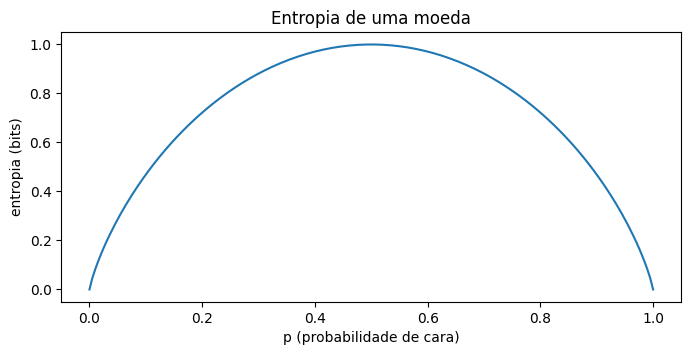

Dado honesto:       2.5850 bits   (log2(6) = 2.5850)
Dado viciado:       2.1610 bits
Espécie (pinguins): 1.5201 bits   scipy: 1.5201   máximo: 1.5850
Ilha (pinguins):    1.4339 bits


In [3]:
def entropia(probs):
    """Entropia em bits. Termos com p = 0 contribuem com zero (o limite de p·log p quando p → 0)."""
    probs = np.asarray(probs, dtype=float)   # aceita listas e Series
    probs = probs[probs > 0]
    return -np.sum(probs * np.log2(probs))


# Entropia de uma moeda em função de p.
ps = np.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(ps, [entropia([p, 1 - p]) for p in ps])
ax.set_xlabel("p (probabilidade de cara)")
ax.set_ylabel("entropia (bits)")
ax.set_title("Entropia de uma moeda")
plt.show()

print(f"Dado honesto:       {entropia([1/6] * 6):.4f} bits   (log2(6) = {np.log2(6):.4f})")
print(f"Dado viciado:       {entropia([0.5, 0.1, 0.1, 0.1, 0.1, 0.1]):.4f} bits")
# scipy.stats.entropy faz a mesma conta (base=2 para bits; o padrão é o log natural).
especies = pinguins["species"].value_counts(normalize=True)
ilhas = pinguins["island"].value_counts(normalize=True)
print(f"Espécie (pinguins): {entropia(especies):.4f} bits   scipy: {stats.entropy(especies, base=2):.4f}   máximo: {np.log2(3):.4f}")
print(f"Ilha (pinguins):    {entropia(ilhas):.4f} bits")

**Conclusão:** a entropia de uma moeda é máxima (**1 bit**) com $p = 0{,}5$ e cai a zero nas pontas, onde o resultado é certo. O dado honesto tem a entropia máxima para 6 resultados (**2,585 bits** = $\log_2 6$); o dado viciado, que dá 6 metade das vezes, é mais previsível (**2,161 bits**).

Nos pinguins, a espécie tem entropia de **1,520 bits**, perto do máximo de 1,585 para 3 classes equilibradas: as três espécies têm frequências razoavelmente parecidas (44%, 36% e 20%). A ilha tem entropia um pouco menor (1,434 bits). Saber a espécie de um pinguim sorteado ao acaso exige, em média, cerca de 1,5 pergunta de "sim ou não".

## 🎓 Conceito: entropia cruzada (a log loss)

Suponha que a distribuição verdadeira é $p$, mas nós **acreditamos** (ou um modelo prevê) que é $q$. A **entropia cruzada** é a surpresa média que sentiremos, já que as nossas surpresas são calculadas com $q$ e os eventos acontecem segundo $p$:

$$H(p, q) = -\sum_x p(x) \log q(x)$$

- Ela é sempre **maior ou igual** à entropia $H(p)$, e só é igual quando $q = p$. Acreditar na distribuição errada **sempre** custa surpresa extra.

Agora, a ponte: num conjunto de dados, cada exemplo tem um rótulo verdadeiro (a distribuição $p$ dele é "100% na classe certa"), e o modelo prevê probabilidades $q$. A entropia cruzada desse exemplo é simplesmente $-\log q(\text{classe certa})$. A média sobre todos os exemplos é a **log loss** do ML-02 (com o log natural). Treinar um classificador minimizando a log loss é **minimizar a surpresa** do modelo diante dos rótulos verdadeiros.

In [4]:
# Três "modelos" prevendo a espécie de 4 pinguins. As classes são [Adelie, Chinstrap, Gentoo].
verdadeiras = np.array([0, 0, 1, 2])
previsoes = {
    "confiante e certo": np.array([[0.90, 0.05, 0.05], [0.90, 0.05, 0.05], [0.05, 0.90, 0.05], [0.05, 0.05, 0.90]]),
    "em dúvida": np.array([[0.40, 0.30, 0.30], [0.40, 0.30, 0.30], [0.30, 0.40, 0.30], [0.30, 0.30, 0.40]]),
    "confiante e errado num caso": np.array([[0.90, 0.05, 0.05], [0.01, 0.98, 0.01], [0.05, 0.90, 0.05], [0.05, 0.05, 0.90]]),
}
from sklearn.metrics import log_loss   # a log loss do ML-02, para conferir
for nome, q in previsoes.items():
    # q[np.arange(4), verdadeiras] pega, em cada linha, a probabilidade dada à classe verdadeira.
    prob_certa = q[np.arange(4), verdadeiras]
    entropia_cruzada = -np.mean(np.log(prob_certa))
    print(f"{nome:>28}: entropia cruzada à mão = {entropia_cruzada:.4f}   log_loss do sklearn = {log_loss(verdadeiras, q, labels=[0, 1, 2]):.4f}")

           confiante e certo: entropia cruzada à mão = 0.1054   log_loss do sklearn = 0.1054
                   em dúvida: entropia cruzada à mão = 0.9163   log_loss do sklearn = 0.9163
 confiante e errado num caso: entropia cruzada à mão = 1.2303   log_loss do sklearn = 1.2303


**Conclusão:** a entropia cruzada calculada à mão é **idêntica** à `log_loss` do scikit-learn nos três casos: a log loss **é** a entropia cruzada.
- O modelo **confiante e certo** tem a menor log loss (**0,105**).
- O modelo **em dúvida**, que acerta a classe mais provável em todos os casos mas com pouca confiança, tem log loss de **0,916**.
- O modelo que acerta três casos com confiança, mas dá apenas **1%** à classe certa de um pinguim, é o **pior** de todos (**1,230**), apesar de acertar 3 dos 4 casos. Sozinho, esse único erro custa $-\ln(0{,}01) = 4{,}6$ de surpresa.

É a mesma lição do notebook 06 do ML-02: a log loss pune com muita força os erros **confiantes**.

## 🎓 Conceito: divergência de Kullback-Leibler (KL)

A **divergência KL** é o **custo extra** de usar $q$ quando a verdade é $p$:

$$D_{KL}(p \,\|\, q) = H(p, q) - H(p) = \sum_x p(x) \log\frac{p(x)}{q(x)}$$

- Ela é sempre $\ge 0$, e é zero só quando $q = p$.
- Ela **não é simétrica**: $D_{KL}(p \| q) \neq D_{KL}(q \| p)$, então não é uma "distância" no sentido usual.
- Se $q$ dá probabilidade **zero** a algo que $p$ considera possível, a KL é **infinita**: é o erro "confiante demais" levado ao extremo.

Como $H(p)$ não depende do modelo, **minimizar a entropia cruzada é o mesmo que minimizar a KL** entre a verdade e o modelo.

🔗 **Ponte para o ML:** a KL aparece no treino de modelos generativos (como os autoencoders variacionais), na destilação de modelos e para medir **mudanças na distribuição** dos dados entre o treino e a produção (*data drift*).

In [5]:
# A distribuição das espécies em cada ilha, comparada com a distribuição geral.
geral = pinguins["species"].value_counts(normalize=True).sort_index()
por_ilha = pd.crosstab(pinguins["island"], pinguins["species"], normalize="index")
print(por_ilha.round(3), "\n")

for ilha in por_ilha.index:
    p = por_ilha.loc[ilha].to_numpy()
    q = geral.to_numpy()
    print(f"{ilha:>10}: KL(ilha ‖ geral) = {stats.entropy(p, q, base=2):.4f} bits   KL(geral ‖ ilha) = {stats.entropy(q, p, base=2):.4f} bits")

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe      0.270      0.000    0.73
Dream       0.447      0.553    0.00
Torgersen   1.000      0.000    0.00 

    Biscoe: KL(ilha ‖ geral) = 0.5636 bits   KL(geral ‖ ilha) = inf bits
     Dream: KL(ilha ‖ geral) = 0.8071 bits   KL(geral ‖ ilha) = inf bits
 Torgersen: KL(ilha ‖ geral) = 1.1896 bits   KL(geral ‖ ilha) = inf bits


**Conclusão:** a ilha **Torgersen** é a mais diferente da distribuição geral (**1,19 bits**), porque só tem Adelie; **Biscoe** é a menos diferente (0,56 bit). E todas as divergências no sentido inverso, KL(geral ‖ ilha), são **infinitas**: a distribuição geral considera possível encontrar, por exemplo, um Chinstrap, enquanto a de Biscoe dá probabilidade **zero** a isso. Usar a distribuição de uma ilha como modelo para a população inteira seria "infinitamente surpreendente" na primeira vez que um Chinstrap aparecesse.

A assimetria importa na prática: um modelo que dá probabilidade zero (ou quase zero) a algo que acontece é punido sem limite. É por isso que modelos de linguagem e classificadores evitam probabilidades exatamente iguais a zero (por exemplo, com a **suavização** do Naive Bayes).

## 🎓 Conceito: impureza, Gini e ganho de informação

Uma árvore de decisão divide os dados em grupos cada vez mais **puros** (com uma só classe). Para escolher uma divisão, ela precisa medir a **impureza** de um grupo:
- **Entropia:** $H = -\sum_k p_k \log_2 p_k$.
- **Índice de Gini:** $G = 1 - \sum_k p_k^2$. É a probabilidade de errar a classe de um exemplo sorteado do grupo se o rotularmos ao acaso, de acordo com as proporções do grupo. É mais barato de calcular (sem logaritmo).

As duas valem zero num grupo puro e são máximas quando as classes estão equilibradas.

O **ganho de informação** de uma divisão é quanto a impureza cai: a impureza do grupo original menos a **média ponderada** das impurezas dos grupos resultantes (ponderada pelo tamanho de cada um). A árvore escolhe, entre todas as divisões possíveis, a de **maior ganho**.

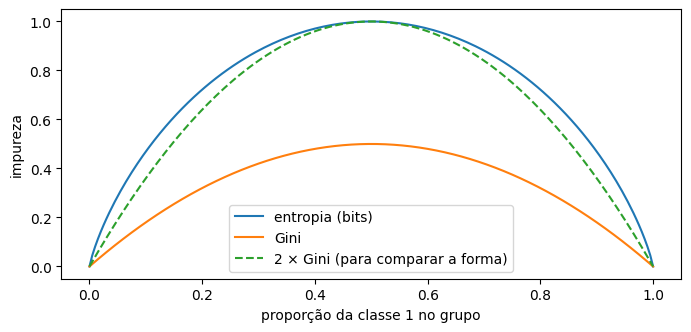

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(ps, [entropia([p, 1 - p]) for p in ps], label="entropia (bits)")
ax.plot(ps, [1 - p**2 - (1 - p)**2 for p in ps], label="Gini")
ax.plot(ps, [2 * (1 - p**2 - (1 - p)**2) for p in ps], linestyle="--", label="2 × Gini (para comparar a forma)")
ax.set_xlabel("proporção da classe 1 no grupo")
ax.set_ylabel("impureza")
ax.legend()
plt.show()

Entropia: melhor limiar = 206.5 mm, ganho = 0.8065 bits (de 1.5201)


Gini:     melhor limiar = 206.5 mm, ganho = 0.3303 (de 0.6384)
sklearn (entropy): limiar escolhido = 206.5 mm
sklearn (gini): limiar escolhido = 206.5 mm

Espécies de cada lado do melhor limiar:
espécie    Adelie  Chinstrap  Gentoo
nadadeira                           
> 206.5         2          5     118
≤ 206.5       144         63       1


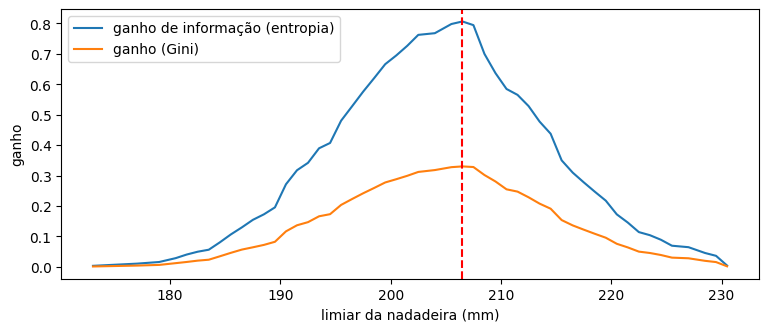

In [7]:
def gini(rotulos):
    p = pd.Series(rotulos).value_counts(normalize=True).to_numpy()
    return 1 - np.sum(p ** 2)


def entropia_rotulos(rotulos):
    return entropia(pd.Series(rotulos).value_counts(normalize=True))


def ganho(x, y, limiar, impureza):
    """Queda da impureza ao dividir em x <= limiar e x > limiar."""
    esquerda, direita = y[x <= limiar], y[x > limiar]
    media_filhos = (len(esquerda) * impureza(esquerda) + len(direita) * impureza(direita)) / len(y)
    return impureza(y) - media_filhos


# Procurando à mão a melhor divisão para separar as 3 espécies pela nadadeira.
x = pinguins["flipper_length_mm"].to_numpy()
y = pinguins["species"].to_numpy()
valores = np.sort(np.unique(x))
limiares = (valores[:-1] + valores[1:]) / 2   # pontos médios entre valores consecutivos (como a árvore faz)
ganhos_entropia = [ganho(x, y, l, entropia_rotulos) for l in limiares]
ganhos_gini = [ganho(x, y, l, gini) for l in limiares]

melhor_ent = limiares[np.argmax(ganhos_entropia)]
melhor_gini = limiares[np.argmax(ganhos_gini)]
print(f"Entropia: melhor limiar = {melhor_ent} mm, ganho = {max(ganhos_entropia):.4f} bits (de {entropia_rotulos(y):.4f})")
print(f"Gini:     melhor limiar = {melhor_gini} mm, ganho = {max(ganhos_gini):.4f} (de {gini(y):.4f})")

# Conferindo com uma árvore de profundidade 1 do scikit-learn (um "toco").
for criterio in ["entropy", "gini"]:
    toco = DecisionTreeClassifier(max_depth=1, criterion=criterio).fit(x.reshape(-1, 1), y)
    print(f"sklearn ({criterio}): limiar escolhido = {toco.tree_.threshold[0]} mm")

print("\nEspécies de cada lado do melhor limiar:")
print(pd.crosstab(np.where(x <= melhor_ent, f"≤ {melhor_ent}", f"> {melhor_ent}"), y,
                  rownames=["nadadeira"], colnames=["espécie"]))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(limiares, ganhos_entropia, label="ganho de informação (entropia)")
ax.plot(limiares, ganhos_gini, label="ganho (Gini)")
ax.axvline(melhor_ent, color="red", linestyle="--")
ax.set_xlabel("limiar da nadadeira (mm)")
ax.set_ylabel("ganho")
ax.legend()
plt.show()

**Conclusão:** as curvas de impureza mostram que entropia e Gini têm **a mesma forma**: zero nos grupos puros e máximo com as classes equilibradas. A entropia (azul) e o Gini multiplicado por 2 (tracejado) quase se sobrepõem.

A busca à mão encontrou o melhor limiar em **206,5 mm**, e os dois critérios concordam entre si **e** com a árvore do scikit-learn. Essa divisão reduz a entropia das espécies de 1,520 para cerca de 0,71 bit (um ganho de **0,807 bit**, mais da metade da incerteza). A tabela mostra o motivo: acima de 206,5 mm ficam **118 dos 119 Gentoo** (com só 7 pinguins de outras espécies); abaixo, ficam quase todos os Adelie e Chinstrap, que a nadadeira sozinha não separa (o histograma do notebook 03 mostrava isso).

No gráfico, as duas curvas de ganho têm o pico no mesmo lugar. Na prática, Gini e entropia quase sempre escolhem divisões parecidas; o Gini é o padrão do scikit-learn só por ser mais rápido.

## 🎓 Conceito: informação mútua

A **informação mútua** entre $X$ e $Y$ mede **quanto saber $X$ reduz a incerteza sobre $Y$**:

$$I(X; Y) = H(Y) - H(Y \mid X)$$

onde $H(Y \mid X)$ é a entropia de $Y$ que **sobra**, em média, depois de conhecer $X$ (exatamente o "ganho de informação" de uma divisão).

- $I(X; Y) = 0$ se e só se $X$ e $Y$ são **independentes**.
- Diferente da correlação, ela detecta **qualquer** tipo de relação, linear ou não. Ela resolve o problema do $Y = X^2$ do notebook 09.

🔗 **Ponte para o ML:** o scikit-learn usa a informação mútua para **selecionar atributos** (`mutual_info_classif` e `mutual_info_regression`), justamente porque ela não se limita a relações lineares.

In [8]:
# Informação mútua entre ilha e espécie, à mão: H(espécie) - H(espécie | ilha).
h_especie = entropia_rotulos(pinguins["species"])
peso_ilha = pinguins["island"].value_counts(normalize=True)
h_condicional = sum(peso_ilha[ilha] * entropia_rotulos(grupo["species"]) for ilha, grupo in pinguins.groupby("island"))
print(f"H(espécie) = {h_especie:.4f} bits   H(espécie | ilha) = {h_condicional:.4f} bits   I(ilha; espécie) = {h_especie - h_condicional:.4f} bits")

# Relações simuladas: a correlação e a informação mútua (estimada pelo scikit-learn, em "nats", unidades do log natural).
x_sim = rng.uniform(-3, 3, 2_000)
relacoes = {
    "linear": 2 * x_sim + rng.normal(0, 1, 2_000),
    "parábola (Y = X² + ruído)": x_sim ** 2 + rng.normal(0, 1, 2_000),
    "seno": np.sin(2 * x_sim) + rng.normal(0, 0.3, 2_000),
    "independente": rng.normal(0, 1, 2_000),
}
linhas = []
for nome, y_sim in relacoes.items():
    im = mutual_info_regression(x_sim.reshape(-1, 1), y_sim, random_state=42)[0]
    linhas.append({"relação": nome, "correlação de Pearson": np.corrcoef(x_sim, y_sim)[0, 1], "informação mútua": im})
print()
print(pd.DataFrame(linhas).set_index("relação"))

H(espécie) = 1.5201 bits   H(espécie | ilha) = 0.7782 bits   I(ilha; espécie) = 0.7419 bits



                           correlação de Pearson  informação mútua
relação                                                           
linear                                    0.9618            1.2188
parábola (Y = X² + ruído)                 0.0368            0.9993
seno                                     -0.4012            0.8636
independente                             -0.0139            0.0000


**Conclusão:** saber a ilha reduz a entropia da espécie de **1,520** para **0,778 bit**: a informação mútua é **0,742 bit**, quase metade da incerteza. Faz sentido: Torgersen só tem Adelie, Biscoe tem 73% de Gentoo (e nenhum Chinstrap), e Dream mistura Adelie e Chinstrap.

Nas relações simuladas, a informação mútua enxerga o que a correlação não vê:
- **Linear:** as duas medidas são altas (correlação **0,96**, informação mútua **1,22**).
- **Parábola:** a correlação é praticamente zero (**0,04**), mas a informação mútua é alta (**1,00**): $X$ diz muito sobre $Y$.
- **Seno:** a correlação (−0,40) captura só uma parte da relação; a informação mútua é alta (**0,86**).
- **Independente:** as duas ficam em zero.

(A informação mútua do scikit-learn é medida em *nats*, com o log natural, e é **estimada** a partir dos dados, então não é exata. Mas ela distingue claramente "há relação" de "não há".)

## 2. Resumo e próximos passos

| Medida | Fórmula | Onde aparece no ML |
|---|---|---|
| Surpresa | $-\log p$ | log loss de um exemplo |
| Entropia | $-\sum p \log p$ | critério `"entropy"` das árvores |
| Entropia cruzada | $-\sum p \log q$ | **log loss** (classificação) |
| Divergência KL | $\sum p \log (p/q)$ | drift, modelos generativos, destilação |
| Gini | $1 - \sum p^2$ | critério padrão das árvores |
| Informação mútua | $H(Y) - H(Y \mid X)$ | seleção de atributos, ganho de informação |

**Conceitos que você aprendeu**
- **Surpresa** e **entropia** (em bits) como medidas de incerteza.
- **Entropia cruzada** = log loss: treinar um classificador é minimizar a surpresa.
- **Divergência KL**, assimétrica e infinita quando o modelo dá probabilidade zero ao que acontece.
- **Gini** × **entropia** e o **ganho de informação**, com uma divisão de árvore calculada à mão.
- **Informação mútua**, que detecta relações não lineares.

**Python novo:** `np.log2`, `np.asarray`, `stats.entropy` (com `base` e com duas distribuições), indexação `q[np.arange(n), classes]`, `DecisionTreeClassifier(max_depth=1)` e `.tree_.threshold`, `mutual_info_regression`, `sum(... for ...)` com um gerador.

**Próximo notebook:** o último da trilha principal volta ao Teorema de Bayes (notebook 06) com outra ambição: em vez de atualizar a probabilidade de um **evento**, vamos atualizar uma **distribuição inteira** sobre um parâmetro. É a **inferência bayesiana**, e ela vai mostrar que a regularização do ML-01 é, na verdade, uma priori disfarçada.